In [1]:
import torch
print(torch.cuda.is_available())  # doit afficher True

True


In [2]:
!pip install -q transformers datasets peft evaluate rouge_score accelerate

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.5 MB/s eta 0:00:00


In [3]:
from datasets import load_dataset

ds = load_dataset("KisanVaani/agriculture-qa-english-only")
print(ds)
print(ds["train"].column_names)
for i in range(3):
    print(ds["train"][i])

README.md:   0%|          | 0.00/1.74k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.97MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/22615 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['question', 'answers'],
        num_rows: 22615
    })
})
['question', 'answers']
{'question': 'why is crop rotation important in farming?', 'answers': 'This helps to prevent soil erosion and depletion, and can also help to control pests and diseases'}
{'question': 'What farming practice helps prevent soil erosion?', 'answers': 'Crop Rotation'}
{'question': 'what is crop rotation', 'answers': 'Crop rotation is the practice of growing a series of different crops in the same area over several seasons'}


In [4]:
# Supprimer les doublons de questions pour éviter une fuite entre train et test
df = ds["train"].to_pandas()
df = df.drop_duplicates(subset="question").reset_index(drop=True)
print("Après dédoublonnage :", len(df))

from datasets import Dataset
full = Dataset.from_pandas(df)

split = full.train_test_split(test_size=0.1, seed=42)
test_valid = split["test"].train_test_split(test_size=0.5, seed=42)

train_ds = split["train"]
val_ds = test_valid["train"]
test_ds = test_valid["test"]
print(len(train_ds), len(val_ds), len(test_ds))

Après dédoublonnage : 2225
2002 111 112


In [5]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

model_name = "google/flan-t5-base"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model_agri = AutoModelForSeq2SeqLM.from_pretrained(model_name).to("cuda")

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

In [6]:
def make_prompt(q):
    return f"Answer the following agricultural question.\n\nQuestion: {q}\n\nAnswer:"

def generate_agri(model, prompt, max_new_tokens=64):
    inputs = tokenizer(prompt, return_tensors="pt").to("cuda")
    out = model.generate(**inputs, max_new_tokens=max_new_tokens)
    return tokenizer.decode(out[0], skip_special_tokens=True)

In [7]:
import evaluate, json

rouge = evaluate.load("rouge")

n = 100
questions = test_ds["question"][:n]
refs = test_ds["answers"][:n]

preds_base = [generate_agri(model_agri, make_prompt(q)) for q in questions]

res_base = rouge.compute(predictions=preds_base, references=refs, use_stemmer=True)
print({k: round(float(v), 4) for k, v in res_base.items()})

with open("agri_baseline_rouge.json", "w") as f:
    json.dump({k: float(v) for k, v in res_base.items()}, f, indent=2)

{'rouge1': 0.0797, 'rouge2': 0.0166, 'rougeL': 0.0732, 'rougeLsum': 0.0729}


In [8]:
for i in range(5):
    print("Q       :", questions[i])
    print("RÉF     :", refs[i])
    print("BASELINE:", preds_base[i])
    print()

Q       : how does nutrient leaching affects cassava yield.
RÉF     : Wetland soils are prone to nutrient leaching due to excessive water movement. The continuous flow of water can carry away essential nutrients from the soil, making them unavailable to cassava plants. Nutrient deficiencies can negatively impact plant growth, development, and overall productivity.
BASELINE: nutrient leaching increases the amount of nutrients in the soil

Q       : when do the intensity of outbreak increases.
RÉF     : during the start of the wet season after a drought, which allows moths to lay eggs in areas of dense vegetation which supports the larval stage growth
BASELINE: during the summer

Q       : how can climate affect soil fertility.
RÉF     : Temperature, rainfall, and other weather factors can affect the rate of nutrient release from fertilizers and the growth and development of crops. For example, high temperatures and low rainfall can lead to rapid nutrient leaching and reduced nutrient av

In [9]:
from peft import LoraConfig, get_peft_model, TaskType

lora_config = LoraConfig(
    r=16, lora_alpha=32, target_modules=["q", "v"],
    lora_dropout=0.05, bias="none", task_type=TaskType.SEQ_2_SEQ_LM,
)
peft_model_agri = get_peft_model(model_agri, lora_config)
peft_model_agri.print_trainable_parameters()

ImportError: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported

In [10]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [1]:
from peft import LoraConfig, get_peft_model, TaskType

lora_config = LoraConfig(
    r=16, lora_alpha=32, target_modules=["q", "v"],
    lora_dropout=0.05, bias="none", task_type=TaskType.SEQ_2_SEQ_LM,
)
peft_model_agri = get_peft_model(model_agri, lora_config)
peft_model_agri.print_trainable_parameters()

NameError: name 'model_agri' is not defined

In [2]:
!pip uninstall -y torchao
!pip install -q transformers datasets peft evaluate rouge_score accelerate

In [1]:
from peft import LoraConfig, get_peft_model, TaskType

lora_config = LoraConfig(
    r=16, lora_alpha=32, target_modules=["q", "v"],
    lora_dropout=0.05, bias="none", task_type=TaskType.SEQ_2_SEQ_LM,
)
peft_model_agri = get_peft_model(model_agri, lora_config)
peft_model_agri.print_trainable_parameters()

NameError: name 'model_agri' is not defined

In [2]:
from datasets import load_dataset, Dataset
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import evaluate, json

# Données
ds = load_dataset("KisanVaani/agriculture-qa-english-only")
df = ds["train"].to_pandas().drop_duplicates(subset="question").reset_index(drop=True)
full = Dataset.from_pandas(df)
split = full.train_test_split(test_size=0.1, seed=42)
test_valid = split["test"].train_test_split(test_size=0.5, seed=42)
train_ds, val_ds, test_ds = split["train"], test_valid["train"], test_valid["test"]
print(len(train_ds), len(val_ds), len(test_ds))  # doit afficher 2002 111 112

# Modèle
model_name = "google/flan-t5-base"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model_agri = AutoModelForSeq2SeqLM.from_pretrained(model_name).to("cuda")

# Fonctions
def make_prompt(q):
    return f"Answer the following agricultural question.\n\nQuestion: {q}\n\nAnswer:"

def generate_agri(model, prompt, max_new_tokens=64):
    inputs = tokenizer(prompt, return_tensors="pt").to("cuda")
    out = model.generate(**inputs, max_new_tokens=max_new_tokens)
    return tokenizer.decode(out[0], skip_special_tokens=True)

# Évaluation
rouge = evaluate.load("rouge")
n = 100
questions = test_ds["question"][:n]
refs = test_ds["answers"][:n]

2002 111 112


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


In [3]:
preds_base = [generate_agri(model_agri, make_prompt(q)) for q in questions]

res_base = rouge.compute(predictions=preds_base, references=refs, use_stemmer=True)
print({k: round(float(v), 4) for k, v in res_base.items()})

with open("agri_baseline_rouge.json", "w") as f:
    json.dump({k: float(v) for k, v in res_base.items()}, f, indent=2)

{'rouge1': 0.0807, 'rouge2': 0.0165, 'rougeL': 0.0726, 'rougeLsum': 0.0725}


In [4]:
from google.colab import files
files.download("agri_baseline_rouge.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
from peft import LoraConfig, get_peft_model, TaskType

lora_config = LoraConfig(
    r=16, lora_alpha=32, target_modules=["q", "v"],
    lora_dropout=0.05, bias="none", task_type=TaskType.SEQ_2_SEQ_LM,
)
peft_model_agri = get_peft_model(model_agri, lora_config)
peft_model_agri.print_trainable_parameters()

trainable params: 1,769,472 || all params: 249,347,328 || trainable%: 0.7096


In [6]:
def preprocess(batch):
    inputs = [make_prompt(q) for q in batch["question"]]
    model_inputs = tokenizer(inputs, max_length=128, truncation=True)
    labels = tokenizer(text_target=batch["answers"], max_length=128, truncation=True)
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tok_train = train_ds.map(preprocess, batched=True, remove_columns=train_ds.column_names)
tok_val = val_ds.map(preprocess, batched=True, remove_columns=val_ds.column_names)

Map:   0%|          | 0/2002 [00:00<?, ? examples/s]

Map:   0%|          | 0/111 [00:00<?, ? examples/s]

In [7]:
from transformers import Seq2SeqTrainer, Seq2SeqTrainingArguments, DataCollatorForSeq2Seq

args = Seq2SeqTrainingArguments(
    output_dir="lora-agri",
    learning_rate=1e-3,
    per_device_train_batch_size=8,
    num_train_epochs=3,
    logging_steps=50,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none",
)

trainer = Seq2SeqTrainer(
    model=peft_model_agri,
    args=args,
    train_dataset=tok_train,
    eval_dataset=tok_val,
    data_collator=DataCollatorForSeq2Seq(tokenizer, model=peft_model_agri),
)
trainer.train()

Epoch,Training Loss,Validation Loss
1,2.829974,2.374799
2,2.672981,2.282686
3,2.582862,2.246909


TrainOutput(global_step=753, training_loss=2.7058455326642648, metrics={'train_runtime': 209.3636, 'train_samples_per_second': 28.687, 'train_steps_per_second': 3.597, 'total_flos': 271477777747968.0, 'train_loss': 2.7058455326642648, 'epoch': 3.0})

In [8]:
preds_lora = [generate_agri(peft_model_agri, make_prompt(q)) for q in questions]

res_lora = rouge.compute(predictions=preds_lora, references=refs, use_stemmer=True)
print({k: round(float(v), 4) for k, v in res_lora.items()})

with open("agri_lora_rouge.json", "w") as f:
    json.dump({k: float(v) for k, v in res_lora.items()}, f, indent=2)

peft_model_agri.save_pretrained("lora-agri-adapter")

{'rouge1': 0.2521, 'rouge2': 0.0828, 'rougeL': 0.2107, 'rougeLsum': 0.2104}


In [9]:
for i in range(5):
    print("Q       :", questions[i])
    print("RÉF     :", refs[i])
    print("BASELINE:", preds_base[i])
    print("LORA    :", preds_lora[i])
    print()

Q       : how does nutrient leaching affects cassava yield.
RÉF     : Wetland soils are prone to nutrient leaching due to excessive water movement. The continuous flow of water can carry away essential nutrients from the soil, making them unavailable to cassava plants. Nutrient deficiencies can negatively impact plant growth, development, and overall productivity.
BASELINE: nutrient leaching increases the amount of nutrients in the soil
LORA    : nutrient leaching affects cassava yields by affecting the plant's nutrient content, causing a decrease in yields.

Q       : when do the intensity of outbreak increases.
RÉF     : during the start of the wet season after a drought, which allows moths to lay eggs in areas of dense vegetation which supports the larval stage growth
BASELINE: during the summer
LORA    : during the first half of the season

Q       : how can climate affect soil fertility.
RÉF     : Temperature, rainfall, and other weather factors can affect the rate of nutrient rel

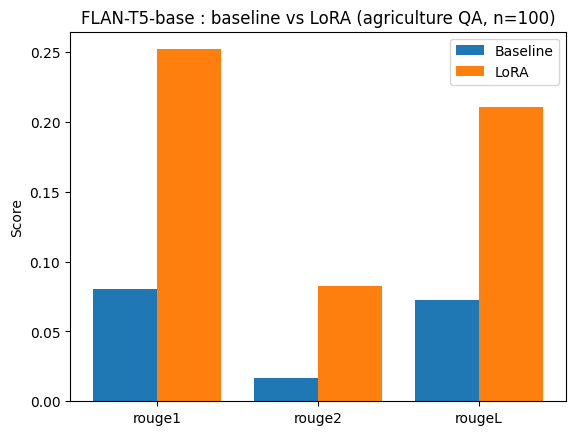

In [10]:
import matplotlib.pyplot as plt

metrics = ["rouge1", "rouge2", "rougeL"]
base = [float(res_base[m]) for m in metrics]
lora = [float(res_lora[m]) for m in metrics]

x = range(len(metrics))
plt.bar([i - 0.2 for i in x], base, width=0.4, label="Baseline")
plt.bar([i + 0.2 for i in x], lora, width=0.4, label="LoRA")
plt.xticks(x, metrics)
plt.ylabel("Score")
plt.title("FLAN-T5-base : baseline vs LoRA (agriculture QA, n=100)")
plt.legend()
plt.savefig("agri_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
import shutil
from google.colab import files

shutil.make_archive("lora-agri-adapter", "zip", "lora-agri-adapter")
for f in ["agri_baseline_rouge.json", "agri_lora_rouge.json",
          "agri_comparison.png", "lora-agri-adapter.zip"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

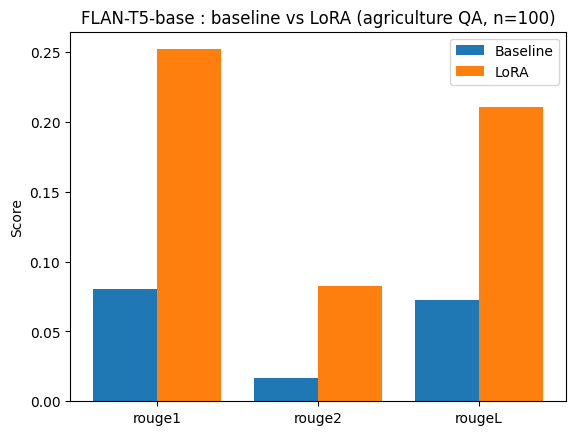

In [12]:
import matplotlib.pyplot as plt

metrics = ["rouge1", "rouge2", "rougeL"]
base = [float(res_base[m]) for m in metrics]
lora = [float(res_lora[m]) for m in metrics]

x = range(len(metrics))
plt.bar([i - 0.2 for i in x], base, width=0.4, label="Baseline")
plt.bar([i + 0.2 for i in x], lora, width=0.4, label="LoRA")
plt.xticks(x, metrics)
plt.ylabel("Score")
plt.title("FLAN-T5-base : baseline vs LoRA (agriculture QA, n=100)")
plt.legend()
plt.savefig("agri_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
import shutil
from google.colab import files

shutil.make_archive("lora-agri-adapter", "zip", "lora-agri-adapter")
for f in ["agri_lora_rouge.json", "agri_comparison.png", "lora-agri-adapter.zip"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
import shutil
from google.colab import files

shutil.make_archive("lora-agri-adapter", "zip", "lora-agri-adapter")
for f in ["agri_lora_rouge.json", "agri_comparison.png", "lora-agri-adapter.zip"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>